# Day 2 — Crypto Risk & Volatility Analyzer: Exploratory Analysis

**Business question:** How much risk did Bitcoin, Ethereum and Solana actually carry over the past year — how far did each fall from its peak, how jumpy were its daily moves, did the coins fall together, and how much return did each deliver per unit of risk?

**Scope:** descriptive, historical risk analysis only. *Educational analysis only — not investment advice.* No buy/sell recommendation, no price prediction. Past volatility and drawdowns do not predict future risk.

Data: Powered by CoinGecko — public API (`market_chart/range`, 2025-11-06 → 2026-11-06), cleaned by `src/data_pipeline.py` into `data/processed/crypto_daily.csv`, `crypto_risk_summary.csv` and `crypto_correlations.csv`. This notebook reads **only** those processed CSVs and recomputes each metric independently via `src/risk_metrics.py` as a spot-check.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def _find_root():
    """Resolve the project root from the notebook file's own location."""
    candidates = []
    try:
        candidates.append(Path(__file__).resolve().parent.parent)
    except NameError:
        pass  # Jupyter: __file__ is not defined; use cwd below.
    candidates.append(Path.cwd())
    candidates.append(Path.cwd().parent)
    for cand in candidates:
        if (cand / "data" / "processed" / "crypto_daily.csv").exists():
            return cand
    raise FileNotFoundError(
        "Could not locate data/processed/crypto_daily.csv from the "
        "notebook location or working directory; run this notebook "
        "from notebooks/ or the project root."
    )


ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
import risk_metrics as rm  # noqa: E402

print('project root:', ROOT)
daily = pd.read_csv(ROOT / 'data/processed/crypto_daily.csv', parse_dates=['date'])
summary = pd.read_csv(ROOT / 'data/processed/crypto_risk_summary.csv')
correlations = pd.read_csv(ROOT / 'data/processed/crypto_correlations.csv')
source = json.loads((ROOT / 'data/processed/data_source.json').read_text())
print('data source:', source)
print('rows:', len(daily), '| coins:', sorted(daily['coin'].unique()))
print('window:', daily['date'].min().date(), 'to', daily['date'].max().date())
LABELS = {'bitcoin': 'Bitcoin (BTC)', 'ethereum': 'Ethereum (ETH)', 'solana': 'Solana (SOL)'}
PALETTE = {'bitcoin': '#F7931A', 'ethereum': '#627EEA', 'solana': '#9945FF'}


project root: /home/hatch/workspace/goals/60-day-data-ai-portfolio/day-02-crypto-risk-volatility-analyzer
data source: {'source': 'live', 'generated_at_utc': '2026-11-06T14:07:00.242684+00:00', 'synthetic': False, 'seed': None, 'window': {'from': '2025-11-06', 'to': '2026-11-06'}, 'coins': ['bitcoin', 'ethereum', 'solana']}
rows: 1098 | coins: ['bitcoin', 'ethereum', 'solana']
window: 2025-11-06 to 2026-11-06


## Q1 — Drawdown: how far did each coin fall from its peak, and did it recover?

Drawdown is the fall from the highest price so far: 0% means the coin is at a new high, −45% means it is 45% below its peak. The table below recomputes the summary from the daily CSV using `risk_metrics.max_drawdown_info` and checks it against the committed summary.

In [2]:
rows = []
for coin, g in daily.groupby('coin'):
    g = g.sort_values('date').reset_index(drop=True)
    info = rm.max_drawdown_info(g['price'], g['date'])
    rows.append({'coin': coin, **info})
recomputed = pd.DataFrame(rows)
check = recomputed.merge(summary, on='coin', suffixes=('_recomputed', '_committed'))
for col in ['max_drawdown', 'peak_date', 'trough_date', 'peak_to_trough_days']:
    assert (check[f'{col}_recomputed'] == check[f'{col}_committed']).all(), col
print('Recomputed drawdowns match the committed summary.')
recomputed[['coin', 'max_drawdown', 'peak_date', 'trough_date',
            'peak_to_trough_days', 'recovery_days', 'recovered_by_end',
            'longest_underwater_days']]

Recomputed drawdowns match the committed summary.


,coin,max_drawdown,peak_date,trough_date,peak_to_trough_days,recovery_days,recovered_by_end,longest_underwater_days
0,bitcoin,-0.447237,2025-11-11,2026-07-01,232,128,False,360
1,ethereum,-0.562421,2025-11-10,2026-06-26,228,133,False,361
2,solana,-0.628521,2025-11-11,2026-06-07,208,152,False,360


## Q2 — Volatility: how jumpy were day-to-day moves?

Rolling 30-day annualised volatility is the standard deviation of daily returns over the last 30 days, multiplied by √365 (crypto trades every day, not 252 days a year).

Rolling volatility recomputed from returns matches crypto_daily.csv.


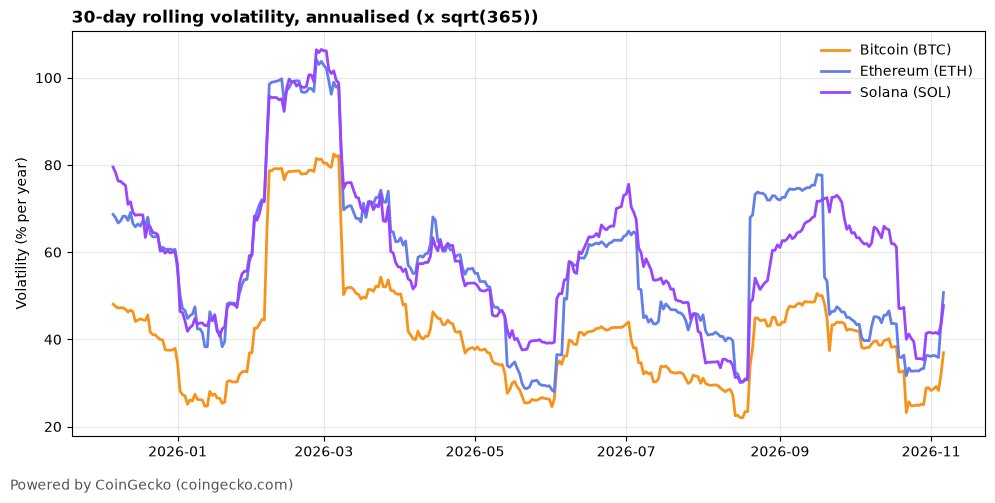

In [3]:
for coin, g in daily.groupby('coin'):
    g = g.sort_values('date')
    vol = rm.rolling_volatility(g['daily_return'])
    assert np.allclose(vol, g['vol_30d_ann'], equal_nan=True)
print('Rolling volatility recomputed from returns matches crypto_daily.csv.')
summary[['coin', 'vol_30d_mean', 'vol_30d_median', 'vol_30d_max', 'vol_30d_max_date']]

fig, ax = plt.subplots(figsize=(10, 5))
for coin, g in daily.groupby('coin'):
    g = g.sort_values('date')
    ax.plot(g['date'], g['vol_30d_ann'] * 100, label=LABELS[coin], color=PALETTE[coin], lw=2)
ax.set_title('30-day rolling volatility, annualised (x sqrt(365))', fontweight='bold', loc='left')
ax.set_ylabel('Volatility (% per year)')
ax.grid(True, alpha=0.3)
ax.legend(frameon=False)
fig.text(0.01, 0.01, 'Powered by CoinGecko (coingecko.com)', fontsize=10, color='#555555')
fig.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

## Q3 — Correlation: did the coins fall together?

Pearson correlation of daily returns. +1 means the coins moved together; a high value means holding all three gave little protection when one fell.

In [4]:
piv = daily.pivot(index='date', columns='coin', values='daily_return')
result = rm.return_correlations(piv)
print('Full-window correlation matrix:')
print(result['full'].round(3))
print()
print('Latest 90 days:', {k: round(v, 3) for k, v in result['latest_90d'].items()})
committed = correlations.set_index('pair')
for pair, row in committed.iterrows():
    assert abs(result['latest_90d'][pair] - row['latest_90d']) < 1e-9
print('Latest-90d values match crypto_correlations.csv.')

Full-window correlation matrix:
coin      bitcoin  ethereum  solana
coin                               
bitcoin     1.000     0.908   0.870
ethereum    0.908     1.000   0.876
solana      0.870     0.876   1.000

Latest 90 days: {'bitcoin-ethereum': 0.899, 'bitcoin-solana': 0.848, 'ethereum-solana': 0.837}
Latest-90d values match crypto_correlations.csv.


## Q4 — Risk-adjusted return: how much return per unit of risk?

Sharpe = mean daily return / std of daily returns × √365. Sortino = mean daily return / downside deviation × √365 (only downside moves count). Both use a 0% risk-free rate, so they are pure return-per-unit-of-volatility measures.

In [5]:
rows = []
for coin, g in daily.groupby('coin'):
    rets = g['daily_return'].dropna()
    rows.append({
        'coin': coin,
        'total_return': g['price'].iloc[-1] / g['price'].iloc[0] - 1,
        'sharpe': rm.sharpe_ratio(rets),
        'sortino': rm.sortino_ratio(rets),
    })
recomputed = pd.DataFrame(rows)
check = recomputed.merge(summary, on='coin', suffixes=('_recomputed', '_committed'))
for col in ['total_return', 'sharpe', 'sortino']:
    assert np.allclose(check[f'{col}_recomputed'], check[f'{col}_committed']), col
print('Sharpe / Sortino recomputed from returns match the committed summary.')
recomputed

Sharpe / Sortino recomputed from returns match the committed summary.


,coin,total_return,sharpe,sortino
0,bitcoin,-0.268326,-0.490781,-0.694885
1,ethereum,-0.347404,-0.406305,-0.590582
2,solana,-0.450765,-0.646686,-0.916392


## Q5 — Tail risk: how bad was a bad day?

Historical one-day VaR 95% is the 5th percentile of daily returns: on 95% of days the loss was no worse than this. CVaR 95% is the average loss on the worst 5% of days — always at least as bad as VaR.

In [6]:
rows = []
for coin, g in daily.groupby('coin'):
    result = rm.var_cvar_95(g['daily_return'].dropna())
    rows.append({'coin': coin, **result})
recomputed = pd.DataFrame(rows)
check = recomputed.merge(summary, on='coin', suffixes=('_recomputed', '_committed'))
for col in ['var_95', 'cvar_95']:
    assert np.allclose(check[f'{col}_recomputed'], check[f'{col}_committed']), col
    assert (check[f'cvar_95_recomputed'] <= check[f'var_95_recomputed']).all()
print('VaR / CVaR recomputed from returns match the committed summary.')
recomputed

VaR / CVaR recomputed from returns match the committed summary.


,coin,var_95,cvar_95
0,bitcoin,-0.033782,-0.050228
1,ethereum,-0.046714,-0.068128
2,solana,-0.052853,-0.070568


## Q6 — Exposure summary: which coin carried the most risk overall?

Solana fell furthest (−62.9% max drawdown), was the jumpiest (mean 30-day volatility 59.6% annualised) and had the worst bad days (VaR 95% −5.3%, CVaR 95% −7.1%) — but also the worst risk-adjusted return (Sharpe −0.65). Ethereum sat in the middle on every measure, and Bitcoin was the calmest of the three while still falling 44.7% from its peak and closing the window 28.3% below it. Correlations of 0.84 to 0.90 in the latest 90 days mean the three coins moved together, so holding all three gave little protection.

*Educational analysis only — not investment advice. Past volatility and drawdowns do not predict future risk.*